# Validation

Separate saved 0A runtime evidence from feature completeness and 0B predictor evidence. Historical or partial receipts are not current acceptance.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = "general/03_validation"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())


## Runtime gates and footprint

The figure reads every gate from a local receipt: a white square means no receipt was found here, not a failed model. The right panels come from the same contract run on one B200 GPU.

model_id,model,pin,kind,known_answer,robustness,token_audit,accepted,accepted_utc,gpu_name,peak_gpu_gb,load_seconds,contract_seconds,live_requests,configured,staged_receipt,full_bank_tokens,bounded_runtime,semantic_review,complete_feature_datasets,observed_utc,source,source_sha256,staged_manifest
jev,jev-1.14.0,1.14.0,hosted,not_applicable,observed,not_applicable,unknown,None,None,NaN,NaN,NaN,NaN,observed,not_applicable,not_applicable,review,unknown,not assessed here,2026-10-29T21:00:00.183761+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_smoke.json,6226659b7be4bdf23cdf0c8365978c40d70dea1bc254aff36fceace6d32487c3,None
liquid,LiquidAI/d1-3B,051bcc464b01b9f92942b364d9586b0ef5912432,open,observed,observed,observed,observed,2026-10-30T13:23:17.387332+00:00,NVIDIA B200,6.538566,4.297721,49.701576,102.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T08:21:14.509740+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\liquid_9ec245d2a03d40f9bca2463e96fcd409.json,414b11f1c57492d80fbaf8fac85771a92d70b9c81793e29a84eb0a8e5895b4f5,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid\_JEVPFN_CHECKPOINT.json
liquid_lfm3,LiquidAI/d1-2B,cfe5760ff5d5998f91d9ac56bd4b2dbd96996d41,open,observed,observed,observed,observed,2026-10-30T13:23:17.575867+00:00,NVIDIA B200,4.112390,16.702619,60.828091,102.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T11:39:19.778468+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\liquid_lfm3_fb5afa385b7948dfab5fb5352524ba42.json,f87cbf10999bb7c3a2b7b027822a128b30ddf8fd684b7a9feec5116ffa650f43,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid_lfm3\_JEVPFN_CHECKPOINT.json
perplexity,perplexity-ai/pplx-decider-v1.1-27b,14c9d90137962d300f3de95633f7b6535e80c5ce,open,observed,observed,observed,observed,2026-10-30T13:23:17.448997+00:00,NVIDIA B200,52.857277,31.841778,141.752177,106.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T08:41:41.848037+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\perplexity_db1723afd7f846dc8f52dba49770fade.json,f9be1fe46c0e0e17f249829692e60d5463b32fe0942d52fc718652b228d2a504,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\perplexity\_JEVPFN_CHECKPOINT.json
cloudflare,Cloudflare/clef-flash,8b2e5fd17c09fd49bc2880b805d5323ec7ff4ff3,open,observed,observed,observed,observed,2026-10-30T13:23:17.474003+00:00,NVIDIA B200,19.913589,12.071956,64.333045,106.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T08:49:56.555572+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\cloudflare_b6122293809044ba9d602c99595cc73f.json,693b3f8159968eac8e32de9d0d2acbb194b7beff53e58c24173ab8fafce8bad5,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\cloudflare\_JEVPFN_CHECKPOINT.json
intern,internlm/Intern-Decision-4B,0e5e6aa7d6d750e2b1504ba11a8136cb58aeb3cd,open,observed,observed,observed,observed,2026-10-30T13:23:17.485489+00:00,NVIDIA B200,10.032857,23.103771,64.141661,102.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T09:01:00.375521+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\intern_d3fea05f63544011859d6a99e819cf50.json,efbbd63f50ecfe417db34f67c301cfe0ac69453efae3f4dd4a8959831f29f8ec,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\intern\_JEVPFN_CHECKPOINT.json
strands,StrandsAgents/strands-decider-2B-

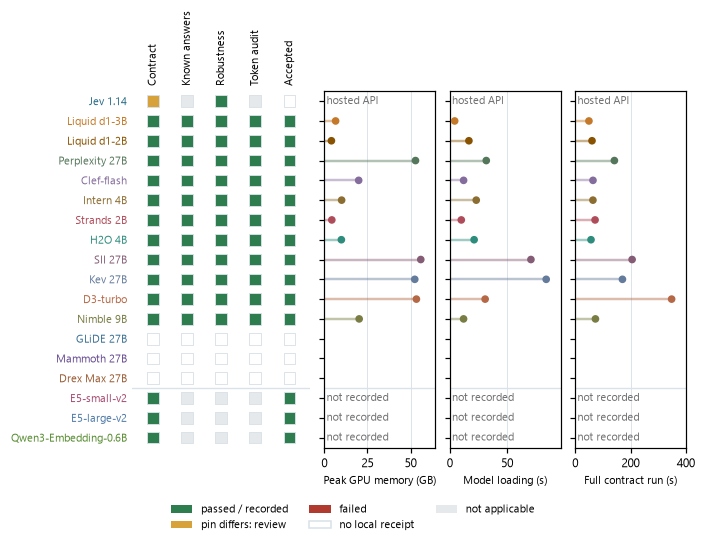

In [2]:
report_section('2. Runtime evidence')
from src.evaluation.notebook_evidence import local_runtime_evidence
from src.visualize.research import runtime_evidence_figure
evidence, token_scope = local_runtime_evidence()
display_table("Runtime pins, receipt provenance and recorded status", evidence, preview_rows=14)
display_json("Exact token audit scope", token_scope)
for fig, name, caption in [runtime_evidence_figure(evidence)]:
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## What each test establishes

CPU tests check input construction, storage/recovery and exact tokenization. GPU/API contracts check actual response semantics and bounded real-text requests. Neither proves full-dataset predictor feasibility.

In [3]:
report_section('3. What each test establishes')
from src.utils.config import load_yaml
display_json("Configured extraction acceptance gates", load_yaml("experiment_0/debug"))
record("Before extraction: review exact token/window coverage, semantic anchors, sensitivity diagnostics, recoverability, spending/rate limits, storage protection and current source/runtime identities. Section 4 reports sensitivity; 0B checks full features and predictors.", "Interpretation")

## Saved representation inventory

Two representations are planned for each extractor/dataset. This counts stored manifest types across versions and does not approve a selected artifact.

dataset_id,model_id,planned,completed
BIN_TEXT_FAKE_JOB_POSTING,jev,2,0
BIN_TEXT_FAKE_JOB_POSTING,liquid,2,2
BIN_TEXT_FAKE_JOB_POSTING,liquid_lfm3,2,0
BIN_TEXT_FAKE_JOB_POSTING,perplexity,2,2
BIN_TEXT_FAKE_JOB_POSTING,cloudflare,2,2
BIN_TEXT_FAKE_JOB_POSTING,strands,2,2
BIN_TEXT_FAKE_JOB_POSTING,intern,2,2
BIN_TEXT_FAKE_JOB_POSTING,h2o,2,2
BIN_TEXT_FAKE_JOB_POSTING,sii,2,2
BIN_TEXT_FAKE_JOB_POSTING,kev,2,0


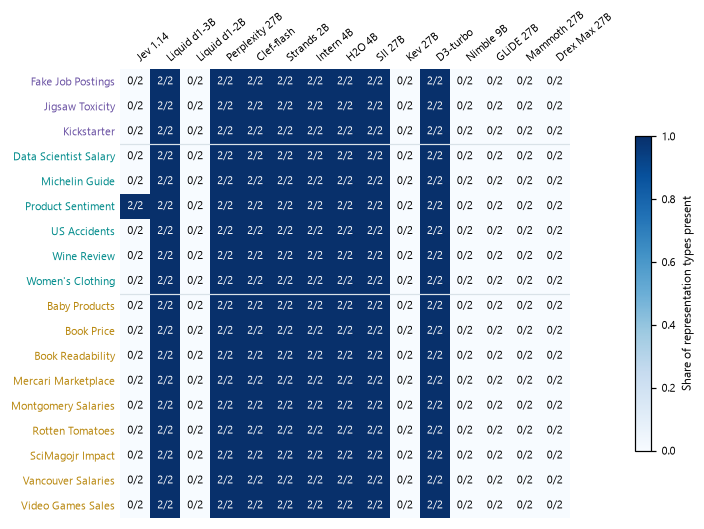

In [4]:
report_section('4. Saved representation inventory')
from src.evaluation.notebook_study import artifact_coverage, predictor_evidence
from src.visualize.study import coverage_figures
inventory = artifact_coverage()
display_table("Saved representation types; not 0B acceptance", inventory, preview_rows=12)
for fig, name, caption in coverage_figures(inventory, "Stored separate and joint representations", feature_inventory=True):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## Predictor contracts and full-fold feasibility

All six fixed predictors and three native-text systems require real runtime checks. Historical reports must not stand in for the current evaluation identity.

In [5]:
report_section('5. Predictor contracts and full-fold feasibility')
predictors = predictor_evidence()
display_table("Nine predictor evidence records", predictors, preview_rows=9)
from src.visualize.study import qualification_figure
if predictors.contract_passed.any() or predictors.profiles_passed.gt(0).any():
    fig = qualification_figure(predictors)
    save(fig, "predictor_qualification", caption="Experiment 0B evidence for each predictor. The left column reports a current synthetic task-contract fit on VSC. The right column gives passing versus required first-outer-fold profiles on real data using the same runtime. Shading marks complete local evidence.")
    display_local(fig)
    plt.close(fig)
record("Required: binary, multiclass including 30 classes, regression, categorical/missing input, joint PCA64 and separate PCA32 at both encoder widths, native text, restart, prediction storage and actual full-training-fold feasibility for both PCA recipes. The benchmark gate checks complete decision and embedding artifacts, prepared PCA for every outer and binary inner training partition, prediction row IDs, and the sealed runtime.", "0B requirements")

model,configured_packages,contract_status,current_evaluation_identity,contract_passed,profiles_passed,profiles_required,full_fold_profile,source
catboost,"{""catboost"": ""1.2.10""}",predictor_contracts_passed_requires_full_fold_profile,False,False,0,22,False,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\after_extraction\predictor_catboost_b53b3a37d1984c90b6c38af4f22d9137.json
tabpfn_3_5,"{""tabpfn"": ""9.0.0""}",not found locally,None,False,0,20,False,None
tabicl_v2,"{""tabicl"": ""2.2.0""}",not found locally,None,False,0,20,False,None
limix_2,"{""LimiX"": ""git:516bf396333feb3198cf7aff8a6c10421f218e24""}",not found locally,None,False,0,20,False,None
kumo_tabular,"{""structured-data-models"": ""git:bd2d55db104679393fcd6afe13305f37e40b5467""}",not found locally,None,False,0,20,False,None
linear,"{""scikit-learn"": ""1.9.1""}",predictor_contracts_passed_requires_full_fold_profile,False,False,0,22,False,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\after_extraction\predictor_linear_fdf4d950a67643feaa90225767917547.json
tabstar,"{""tabstar"": ""1.2.2"", ""transformers"": ""4.57.6""}",not found locally,None,False,0,4,False,None
contexttab,"{""sap-rpt-oss"": ""git:a0067b3c9db56bc35a6dcab09a9223a3ff0821e0""}",not found locally,None,False,0,4,False,None
ag_mm,"{""autogluon.multimodal"": ""1.6.1""}",not found locally,None,False,0,4,False,None


## Complete report

In [6]:
finish_report(NOTEBOOK, save.summary() + "\nOnly saved evidence was analysed; no inference, model training or live VSC changes were performed.")

general/03_validation

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "600fa60cb9934c73457ba1f3e1748defe8f5a20df328559095f251785baec773",
  "git_head": "2b9ea5ec1e733f8f00faf20ba08661a80474c578",
  "git_dirty": true,
  "tfm_library_pin": "43d4938e50fab660d942d4b79cbaca61544c27cf dm-library (remotes/origin/HEAD)\n c08b03530c4f0f9019cd1cd59e749c97dabcbfac tfm-library (remotes/origin/HEAD)\n 710d1c3e0cd5f153a7d5eafcf83f6d51703c1bf6 vsc-library (heads/main-1-g710d1c3)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Runtime evidence


Runtime pins, receipt provenance and recorded status
            model_id                                            model                                      pin    kind   known_answer     robustness    token_audit accepted                     accepted_utc    gpu_name  peak_gpu_gb  load_sec